# PMLDL Assignment 3 · Text-to-Image Generation
## Food and tabletop photography with MS COCO

**Question.** How does training on captioned COCO food photos change what Stable Diffusion v1.5 generates? We fine-tune the U-Net's text cross-attention with LoRA and compare the adapted model with its pretrained starting point at identical prompts and seeds.

**Colab.** Select **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. The notebook downloads public data and model weights. It needs no credentials or external checkpoint from this experiment.

[MS COCO](https://cocodataset.org/#home) · [Stable Diffusion v1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [LoRA training reference](https://huggingface.co/docs/diffusers/training/lora)

In [1]:
%pip -q install diffusers==0.35.2 transformers==4.56.2 peft==0.17.1 accelerate==1.10.1
import gc
import io
import json
import os
import random
import re
import time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from textwrap import fill
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import requests
import torch
from huggingface_hub import model_info
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from torch.nn import functional as F
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Select a T4 GPU in Colab before running."
DEVICE = torch.device("cuda")
DTYPE = torch.float16
SEED = 2026
torch.manual_seed(SEED)
ROOT = Path("/content/pmldl_coco")
ROOT.mkdir(exist_ok=True)
COCO = "https://s3.amazonaws.com/images.cocodataset.org"
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RESOLUTION = 384
TRAIN_PER_CLASS, VAL_PER_CLASS = 100, 12
STEPS, ACCUMULATION, LR = 240, 2, 1e-4
print(f"PyTorch {torch.__version__} | {torch.cuda.get_device_name()} | {RESOLUTION} × {RESOLUTION}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
PyTorch 2.14.1+cu130 | Tesla T4 | 384 × 384


### 1. Build a captioned food dataset

Use the official COCO 2017 train and validation splits. For each of six food categories, require an instance annotation and at least one human-written caption naming that food. A fixed seed determines selection order. Each image appears at most once per split. All usable mentions of the selected food remain available as caption variants. The main gallery uses a separate set of authored prompts.

Apply EXIF orientation, convert to RGB, resize and center-crop to a square with bicubic resampling, and normalize pixels to $[-1,1]$. Some COCO captions describe details outside the center crop.

train2017 | pizza    | 100 usable images
train2017 | sandwich | 100 usable images
train2017 | cake     | 100 usable images
train2017 | donut    | 100 usable images
train2017 | banana   | 100 usable images
train2017 | broccoli | 100 usable images
val2017   | pizza    | 12 usable images
val2017   | sandwich | 12 usable images
val2017   | cake     | 12 usable images
val2017   | donut    | 12 usable images
val2017   | banana   | 12 usable images
val2017   | broccoli | 12 usable images
600 training photos / 2232 captions | 72 held-out photos / 276 captions


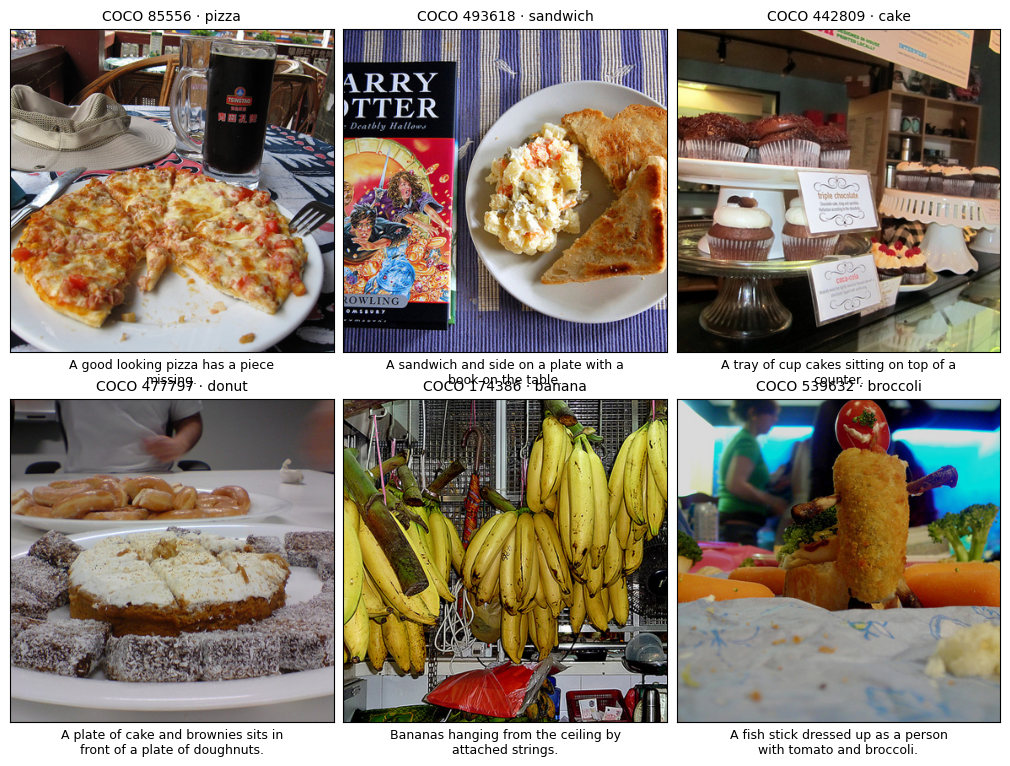

In [2]:
FOODS = {
    "pizza": r"pizzas?", "sandwich": r"sandwich(?:es)?", "cake": r"cakes?",
    "donut": r"(?:doughnut|donut)s?", "banana": r"bananas?", "broccoli": r"broccoli",
}

archive = ROOT / "annotations_trainval2017.zip"
if not archive.exists():
    with requests.get(f"{COCO}/annotations/{archive.name}", stream=True, timeout=(15, 90)) as response:
        response.raise_for_status()
        temp = archive.with_suffix(".partial")
        with temp.open("wb") as output:
            for block in response.iter_content(1 << 20):
                output.write(block)
    temp.replace(archive)

def candidates_for(split, seed):
    with ZipFile(archive) as source:
        with source.open(f"annotations/instances_{split}.json") as file:
            instances = json.load(file)
        with source.open(f"annotations/captions_{split}.json") as file:
            captions = json.load(file)
    category_ids = {c["id"]: c["name"] for c in instances["categories"] if c["name"] in FOODS}
    labels = defaultdict(set)
    for annotation in instances["annotations"]:
        category = category_ids.get(annotation["category_id"])
        if category and not annotation["iscrowd"]:
            labels[annotation["image_id"]].add(category)
    del instances
    names = {i["id"]: i["file_name"] for i in captions["images"]
             if min(i["width"], i["height"]) >= 200}
    groups = {food: defaultdict(list) for food in FOODS}
    for row in captions["annotations"]:
        image_id = row["image_id"]
        if image_id not in names:
            continue
        caption = " ".join(row["caption"].split())
        for food in sorted(labels.get(image_id, ())):
            if re.search(rf"\b{FOODS[food]}\b", caption, flags=re.I):
                groups[food][image_id].append(caption)
    rng = random.Random(seed)
    result = {}
    for food, images in groups.items():
        ids = sorted(images)
        rng.shuffle(ids)
        result[food] = [(image_id, names[image_id], sorted(set(images[image_id])))
                        for image_id in ids]
    return result

def fetch_image(task):
    split, filename = task
    path = ROOT / split / filename
    if not path.exists():
        for attempt in range(3):
            try:
                response = requests.get(f"{COCO}/{split}/{filename}", timeout=(8, 18))
                response.raise_for_status()
                with Image.open(io.BytesIO(response.content)) as image:
                    image.verify()
                path.write_bytes(response.content)
                break
            except (requests.RequestException, OSError):
                if attempt == 2:
                    return None
                time.sleep(0.25 * (attempt + 1))
    return path

def load_split(split, per_class, seed):
    candidates = candidates_for(split, seed)
    (ROOT / split).mkdir(exist_ok=True)
    used = set()
    rows = []
    with ThreadPoolExecutor(max_workers=20) as pool:
        for food, images in candidates.items():
            count = 0
            available = [r for r in images if r[0] not in used]
            for offset in range(0, len(available), per_class):
                batch = available[offset:offset + per_class]
                paths = pool.map(fetch_image, [(split, row[1]) for row in batch])
                for row, path in zip(batch, paths):
                    if path is not None and count < per_class:
                        image_id, _, captions = row
                        rows.append((image_id, food, path, captions))
                        used.add(image_id)
                        count += 1
                if count == per_class:
                    break
            if count < per_class:
                raise RuntimeError(f"{split}: downloaded only {count}/{per_class} {food} images")
            print(f"{split:9s} | {food:8s} | {count} usable images", flush=True)
    random.Random(seed + 100).shuffle(rows)
    return rows

def crop_photo(path):
    with Image.open(path) as opened:
        rgb = ImageOps.exif_transpose(opened).convert("RGB")
        return ImageOps.fit(rgb, (RESOLUTION, RESOLUTION), Image.Resampling.BICUBIC)

train = load_split("train2017", TRAIN_PER_CLASS, SEED)
val = load_split("val2017", VAL_PER_CLASS, SEED + 1)
assert len({row[0] for row in train + val}) == len(train) + len(val)
assert Counter(row[1] for row in train) == dict.fromkeys(FOODS, TRAIN_PER_CLASS)
assert Counter(row[1] for row in val) == dict.fromkeys(FOODS, VAL_PER_CLASS)
print(f"{len(train)} training photos / {sum(len(r[3]) for r in train)} captions | "
      f"{len(val)} held-out photos / {sum(len(r[3]) for r in val)} captions")
fig, axes = plt.subplots(2, 3, figsize=(10, 7.4), layout="constrained")
for ax, food in zip(axes.flat, FOODS):
    image_id, _, path, captions = next(row for row in train if row[1] == food)
    ax.imshow(crop_photo(path))
    ax.set_title(f"COCO {image_id} · {food}", fontsize=10)
    ax.set_xlabel(fill(captions[0], 39), fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

### 2. Encode images and captions and define the diffusion objective

Stable Diffusion uses a pretrained variational autoencoder (VAE) for image latents, a CLIP tokenizer and text encoder for caption features, and a conditional U-Net for denoising. Cache one latent per cropped image and one embedding per caption. The VAE and text encoder stay frozen.

For latent $z_0$, choose a timestep and Gaussian noise $epsilon$. The forward process forms $z_t=sqrt{ar{alpha}_t}z_0+sqrt{1-ar{alpha}_t}epsilon$. The training loss is the mean squared error between the U-Net noise prediction and $epsilon$. Rank-8 LoRA updates the query, key, value and output projections of the U-Net's text cross-attention. Its initial weight update is zero.

[Latent Diffusion](https://arxiv.org/abs/2112.10752) · [DDPM](https://arxiv.org/abs/2006.11239) · [LoRA](https://arxiv.org/abs/2106.09685)

In [3]:
from diffusers import AutoencoderKL, DDPMScheduler, DDIMScheduler, UNet2DConditionModel
from peft import LoraConfig, get_peft_model_state_dict
from safetensors.torch import save_file
from transformers import CLIPTextModel, CLIPTokenizer

revision = model_info(MODEL_ID).sha
print("Stable Diffusion revision:", revision, flush=True)
options = dict(revision=revision, torch_dtype=DTYPE, variant="fp16", use_safetensors=True)
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer", revision=revision)
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder", **options)
text_encoder.eval().requires_grad_(False).to(DEVICE)
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae", **options)
vae.eval().requires_grad_(False).to(DEVICE)
schedule = DDPMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler", revision=revision)
assert schedule.config.prediction_type == "epsilon"

@torch.no_grad()
def encode_text(prompts):
    token_ids = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                          truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    return text_encoder(token_ids).last_hidden_state

def pixels(path):
    array = np.array(crop_photo(path), dtype=np.float32)
    return torch.from_numpy(array).permute(2, 0, 1).div(127.5).sub(1)

@torch.no_grad()
def cache_split(rows, name):
    latents, embeddings = [], []
    for start in tqdm(range(0, len(rows), 12), desc=f"Encode {name}"):
        batch = rows[start:start + 12]
        x = torch.stack([pixels(row[2]) for row in batch]).to(DEVICE, DTYPE)
        latent = vae.encode(x).latent_dist.mode() * vae.config.scaling_factor
        latents.append(latent.cpu())
        texts = [caption for row in batch for caption in row[3]]
        hidden = encode_text(texts).cpu()
        offset = 0
        for row in batch:
            count = len(row[3])
            embeddings.append(hidden[offset:offset + count].clone())
            offset += count
    z = torch.cat(latents)
    assert z.shape == (len(rows), 4, RESOLUTION // 8, RESOLUTION // 8)
    assert torch.isfinite(z).all()
    return z, embeddings

train_latents, train_text = cache_split(train, "train")
val_latents, val_text = cache_split(val, "validation")
assert pixels(train[0][2]).abs().max() <= 1
print(f"Latents {tuple(train_latents.shape)} | caption features {tuple(train_text[0].shape[1:])}")

unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet", **options)
unet.requires_grad_(False).to(DEVICE)
target = r".*\.attn2\.(to_q|to_k|to_v|to_out\.0)"
unet.add_adapter(LoraConfig(r=8, lora_alpha=8, init_lora_weights="gaussian", target_modules=target))
trainable = [p for p in unet.parameters() if p.requires_grad]
for p in trainable:
    p.data = p.data.float()
assert trainable and all("lora_" in name for name, p in unet.named_parameters() if p.requires_grad)
fraction = sum(p.numel() for p in trainable) / sum(p.numel() for p in unet.parameters())
print(f"{sum(p.numel() for p in trainable):,} trainable U-Net parameters ({fraction:.3%})")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Stable Diffusion revision: 451f4fe16113bff5a5d2269ed5ad43b0592e9a14


`torch_dtype` is deprecated! Use `dtype` instead!


Latents (600, 4, 48, 48) | caption features (77, 768)


795,648 trainable U-Net parameters (0.092%)


### 3. Train the adapters and validate on held-out photos

AdamW updates the LoRA weights. Each microbatch selects a caption variant and samples fresh noise and a timestep. Two microbatches contribute to each update. Fixed latent, caption, timestep and noise inputs make the held-out denoising loss comparable across checkpoints. The final budget is fixed before evaluating the generated images.

40/240 | train 0.16340 | validation 0.19540 | 0.4 min
80/240 | train 0.14816 | validation 0.19481 | 0.9 min
120/240 | train 0.17068 | validation 0.19462 | 1.3 min
160/240 | train 0.14429 | validation 0.19459 | 1.7 min
200/240 | train 0.18283 | validation 0.19459 | 2.2 min
240/240 | train 0.20207 | validation 0.19459 | 2.6 min
240 applied updates | 0 mixed-precision skips | adapter saved in this runtime


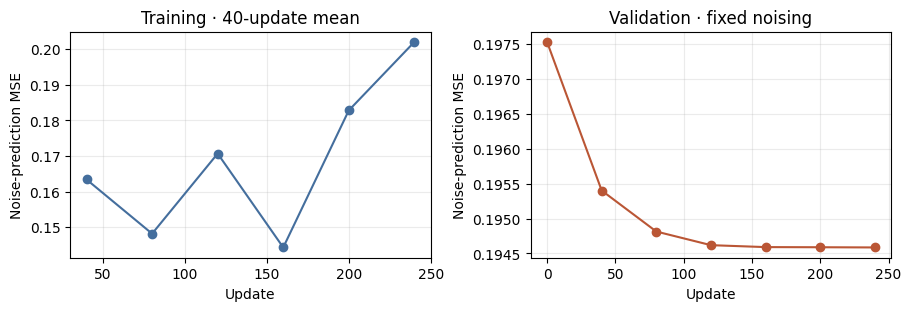

In [4]:
def noise_batch(latents, embeddings, rng):
    z = latents.to(DEVICE, DTYPE)
    text = embeddings.to(DEVICE, DTYPE)
    eps = torch.randn(z.shape, device=DEVICE, dtype=DTYPE, generator=rng)
    t = torch.randint(schedule.config.num_train_timesteps, (len(z),), device=DEVICE, generator=rng)
    noisy = schedule.add_noise(z, eps, t)
    return noisy, t, text, eps

def denoising_loss(batch):
    noisy, t, text, eps = batch
    with torch.autocast("cuda", dtype=DTYPE):
        prediction = unet(noisy, t, encoder_hidden_states=text).sample
    return F.mse_loss(prediction.float(), eps.float())

val_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
fixed_val = noise_batch(val_latents, torch.stack([variants[0] for variants in val_text]), val_rng)

@torch.no_grad()
def validation_loss():
    unet.eval()
    loss = sum(
        denoising_loss(tuple(item[i:i+4] for item in fixed_val)).item()
        for i in range(0, len(val), 4)
    ) / (len(val) // 4)
    unet.train()
    return loss

history = [(0, None, validation_loss())]
unet.enable_gradient_checkpointing()
optimizer = torch.optim.AdamW(trainable, lr=LR)
scaler = torch.amp.GradScaler("cuda")
train_rng = random.Random(SEED + 3)
noise_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 4)
order = list(range(len(train)))
train_rng.shuffle(order)
cursor = 0
window = 0.0
skips = 0
start = time.perf_counter()
for step in range(1, STEPS + 1):
    optimizer.zero_grad(set_to_none=True)
    for _ in range(ACCUMULATION):
        index = order[cursor]
        cursor += 1
        if cursor == len(order):
            train_rng.shuffle(order)
            cursor = 0
        variants = train_text[index]
        text = variants[train_rng.randrange(len(variants))].unsqueeze(0)
        loss = denoising_loss(noise_batch(train_latents[index:index+1], text, noise_rng))
        window += loss.detach().item()
        scaler.scale(loss / ACCUMULATION).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(trainable, 1.0)
    old_scale = scaler.get_scale()
    scaler.step(optimizer)
    scaler.update()
    skips += int(scaler.get_scale() < old_scale)
    if step % 40 == 0:
        training = window / (40 * ACCUMULATION)
        validated = validation_loss()
        assert np.isfinite([training, validated]).all()
        history.append((step, training, validated))
        window = 0.0
        print(f"{step}/{STEPS} | train {training:.5f} | validation {validated:.5f} | "
              f"{(time.perf_counter()-start)/60:.1f} min", flush=True)

adapter = get_peft_model_state_dict(unet)
assert any(torch.count_nonzero(v).item() for k, v in adapter.items() if "lora_B" in k)
save_file({k: v.detach().cpu() for k, v in adapter.items()}, str(ROOT / "coco-food-lora.safetensors"))
print(f"{STEPS - skips} applied updates | {skips} mixed-precision skips | adapter saved in this runtime")
unet.disable_gradient_checkpointing()
unet.eval()
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for ax, series, label, color in [(axes[0], history[1:], "Training · 40-update mean", "#446e9d"),
                                (axes[1], history, "Validation · fixed noising", "#ba5635")]:
    ax.plot([row[0] for row in series], [row[1 if ax is axes[0] else 2] for row in series],
            "o-", color=color)
    ax.set(title=label, xlabel="Update", ylabel="Noise-prediction MSE")
    ax.grid(alpha=.25)
plt.show()

### 4. Generate paired samples from Gaussian noise

The sampler begins with Gaussian latents. At each DDIM step, the U-Net predicts noise for both the caption and an empty string. Classifier-free guidance uses $epsilon_u+w(epsilon_c-epsilon_u)$ with $w=7.5$. The scheduler takes a reverse step, and the VAE decodes the final latent into RGB.

The primary gallery includes six authored prompts and a fixed seed per prompt. Two additional seeds per prompt are used for scoring. Switching LoRA off and on keeps the initial noise, sampler, resolution, and prompts fixed. A second gallery changes the food while holding the wording and initial seed fixed.

[DDIM](https://arxiv.org/abs/2010.02502) · [Classifier-free guidance](https://arxiv.org/abs/2207.12598)

In [5]:
PROMPTS = [
    ("pizza", "A pepperoni pizza on a wooden table next to a glass of water."),
    ("sandwich", "A sliced toasted sandwich on a blue ceramic plate."),
    ("cake", "A chocolate cake topped with strawberries on a white plate."),
    ("donut", "Two pink frosted donuts beside a cup of coffee on a table."),
    ("banana", "A bunch of ripe bananas in a ceramic bowl on a kitchen counter."),
    ("broccoli", "Steamed broccoli on a white dinner plate beside a fork."),
]
SCORE_SEEDS = [101, 202, 303]
jobs = [(food, prompt, seed) for food, prompt in PROMPTS for seed in SCORE_SEEDS]
swap = [(food, f"A photo of {article} {food} on a white plate on a wooden table.", 821)
        for food, article in [("pizza", "a"), ("sandwich", "a"), ("cake", "a"), ("donut", "a")]]
assert not ({p.casefold() for _, p, _ in jobs + swap} &
            {c.casefold() for row in train for c in row[3]})

@torch.no_grad()
def sample(batch, collect_trace=False):
    negative = encode_text([""] * len(batch))
    positive = encode_text([prompt for _, prompt, _ in batch])
    embeds = torch.cat([negative, positive])
    scheduler = DDIMScheduler.from_config(schedule.config)
    scheduler.set_timesteps(24, device=DEVICE)
    latent = torch.stack([
        torch.randn((4, RESOLUTION // 8, RESOLUTION // 8), device=DEVICE, dtype=DTYPE,
                    generator=torch.Generator(device=DEVICE).manual_seed(seed))
        for _, _, seed in batch
    ]) * scheduler.init_noise_sigma
    trace = [latent[:1].clone()] if collect_trace else []
    for i, timestep in enumerate(scheduler.timesteps, 1):
        latent_input = scheduler.scale_model_input(torch.cat([latent, latent]), timestep)
        with torch.autocast("cuda", dtype=DTYPE):
            uncond, cond = unet(latent_input, timestep, encoder_hidden_states=embeds).sample.chunk(2)
        guided = uncond + 7.5 * (cond - uncond)
        latent = scheduler.step(guided, timestep, latent, eta=0.0).prev_sample
        if collect_trace and i in (6, 12, 18, 24):
            trace.append(latent[:1].clone())

    def decode(z):
        x = vae.decode(z / vae.config.scaling_factor).sample
        assert torch.isfinite(x).all()
        x = x.float().mul(.5).add(.5).clamp(0, 1)
        return [Image.fromarray(a) for a in x.mul(255).round().byte().permute(0, 2, 3, 1).cpu().numpy()]

    return decode(latent), decode(torch.cat(trace)) if trace else []

def generate_all(tasks, with_trace=False):
    images = []
    trace = []
    for i in tqdm(range(0, len(tasks), 3), desc="DDIM groups"):
        output, frames = sample(tasks[i:i+3], collect_trace=with_trace and i == 0)
        images.extend(output)
        trace.extend(frames)
    return images, trace

unet.disable_adapters()
base_images, _ = generate_all(jobs)
unet.enable_adapters()
tuned_images, denoising = generate_all(jobs, with_trace=True)
swap_images, _ = generate_all(swap)
assert len(base_images) == len(tuned_images) == 18
assert any(a.tobytes() != b.tobytes() for a, b in zip(base_images, tuned_images))

fig, axes = plt.subplots(3, 4, figsize=(13, 10.4), layout="constrained")
for i, (_, prompt) in enumerate(PROMPTS):
    index = i * len(SCORE_SEEDS)
    for j, (name, pictures) in enumerate([("Pretrained", base_images), ("COCO LoRA", tuned_images)]):
        ax = axes[i // 2, 2 * (i % 2) + j]
        ax.imshow(pictures[index])
        ax.set_title(f"{name} · seed {SCORE_SEEDS[0]}", fontsize=11)
        if j == 0:
            ax.set_xlabel(fill(prompt, 37), fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
fig.suptitle("Same prompt and seed, before and after COCO fine-tuning", fontsize=15)
plt.show()

fig, axes = plt.subplots(1, len(swap), figsize=(11, 3.2), layout="constrained")
for ax, (food, _, _), photo in zip(axes, swap, swap_images):
    ax.imshow(photo)
    ax.set_title(food.title())
    ax.axis("off")
fig.suptitle("COCO LoRA · change the food, keep the plate, table and seed fixed")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(11, 2.6), layout="constrained")
for ax, photo, label in zip(axes, denoising, ["Initial latent", "Step 6", "Step 12", "Step 18", "Step 24"]):
    ax.imshow(photo)
    ax.set_title(label)
    ax.axis("off")
fig.suptitle("Decoded snapshots of the reverse diffusion process")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

### 5. Measure prompt agreement

For each of the 18 matched generations, score the image against its full prompt with a frozen CLIP ViT-B/32 evaluator. Also test which of the six food labels it ranks highest. The food-label check focuses on object identity. CLIP may overlook object counts, spatial relationships, and fine details. These results describe a small paired prompt set, with held-out COCO photos shown as a reference for the food-label probe.

In [6]:
from transformers import CLIPModel, CLIPProcessor

unet.to("cpu")
vae.to("cpu")
text_encoder.to("cpu")
gc.collect()
torch.cuda.empty_cache()
score_id = "openai/clip-vit-base-patch32"
scorer = CLIPModel.from_pretrained(score_id).eval().to(DEVICE)
processor = CLIPProcessor.from_pretrained(score_id)
food_names = list(FOODS)
food_captions = [f"a photograph of {'a bunch of' if food == 'banana' else ''} {food}"
                 for food in food_names]
texts = [prompt for _, prompt in PROMPTS] + food_captions

@torch.no_grad()
def similarities(images):
    rows = []
    for i in range(0, len(images), 12):
        batch = processor(text=texts, images=images[i:i+12], padding=True, return_tensors="pt").to(DEVICE)
        result = scorer(**batch)
        cosine = F.normalize(result.image_embeds.float(), dim=1) @ F.normalize(result.text_embeds.float(), dim=1).T
        rows.append(cosine.cpu().numpy())
    return np.concatenate(rows)

def food_accuracy(scores, classes):
    actual = np.array([food_names.index(food) for food in classes])
    return (scores[:, len(PROMPTS):].argmax(axis=1) == actual).mean()

base_scores, tuned_scores = (similarities(images) for images in (base_images, tuned_images))
indices = np.arange(len(jobs))
prompt_ids = np.repeat(np.arange(len(PROMPTS)), len(SCORE_SEEDS))
base_matching = base_scores[indices, prompt_ids]
tuned_matching = tuned_scores[indices, prompt_ids]
labels = [food for food, _, _ in jobs]
base_food = food_accuracy(base_scores, labels)
tuned_food = food_accuracy(tuned_scores, labels)
real_food = food_accuracy(similarities([crop_photo(r[2]) for r in val]), [r[1] for r in val])
delta = tuned_matching - base_matching
display(Markdown(f'''
| Metric | Pretrained | COCO LoRA |
|---|---:|---:|
| Held-out denoising MSE (72 photographs) | {history[0][2]:.5f} | {history[-1][2]:.5f} |
| Full prompt CLIP cosine (18 generations) | {base_matching.mean():.4f} | {tuned_matching.mean():.4f} |
| Requested food ranked first (18 generations) | {base_food:.1%} | {tuned_food:.1%} |

Mean paired CLIP change **{delta.mean():+.4f}**. The fine-tuned model scored higher on **{sum(delta > 0)}/{len(delta)}** pairs. The food-label evaluator ranked the annotated class first on **{real_food:.1%}** of the held-out reference photos.
'''))
for food, change in zip(food_names, delta.reshape(len(PROMPTS), -1).mean(axis=1)):
    print(f"{food:8s} | paired cosine change {change:+.4f}")
print("RESULTS COMPLETE")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.



| Metric | Pretrained | COCO LoRA |
|---|---:|---:|
| Held-out denoising MSE (72 photographs) | 0.19753 | 0.19459 |
| Full prompt CLIP cosine (18 generations) | 0.3260 | 0.3284 |
| Requested food ranked first (18 generations) | 94.4% | 100.0% |

Mean paired CLIP change **+0.0024**. The fine-tuned model scored higher on **8/18** pairs. The food-label evaluator ranked the annotated class first on **88.9%** of the held-out reference photos.


pizza    | paired cosine change -0.0012
sandwich | paired cosine change -0.0068
cake     | paired cosine change +0.0001
donut    | paired cosine change +0.0113
banana   | paired cosine change +0.0105
broccoli | paired cosine change +0.0003
RESULTS COMPLETE


### Submission

Save the notebook with its training logs, loss plots, generated images, and evaluation table visible. Download it from Colab with **File → Download → Download .ipynb** and upload that single file to Moodle. The assignment lists no separate report, image archive, or model checkpoint.

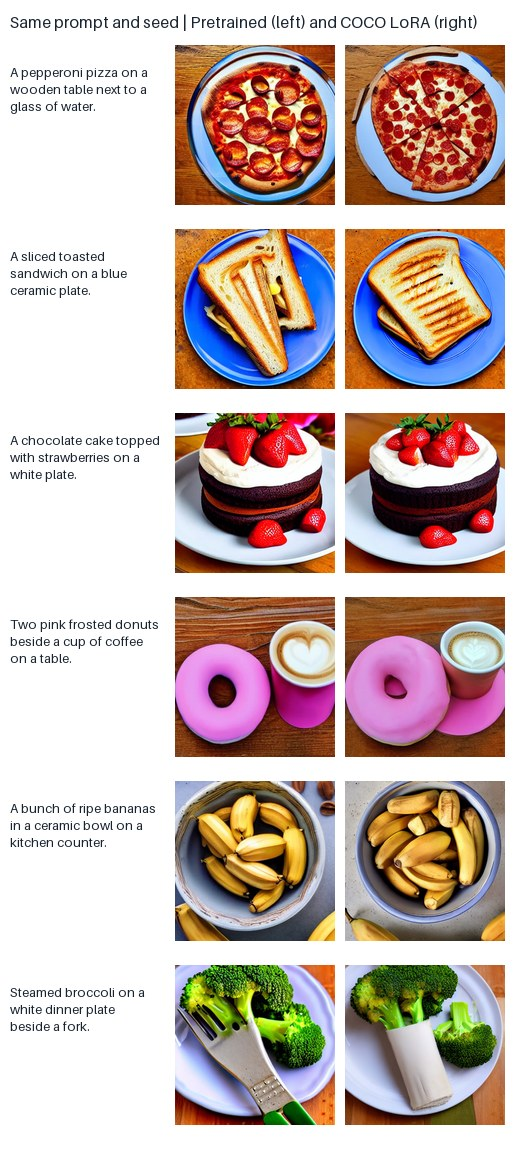

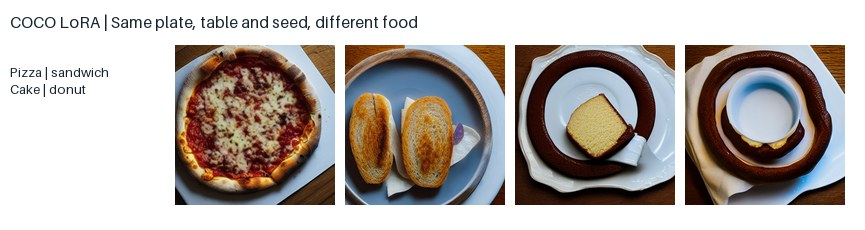

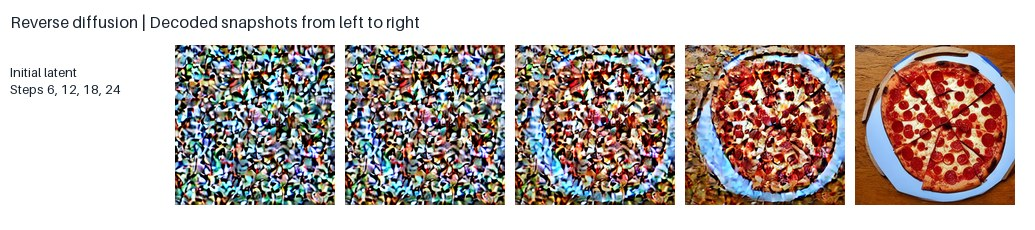

Three compact generation galleries embedded.


In [9]:
# Save compact, portable copies of the three generation figures.
from IPython.display import Image as NotebookImage
from PIL import ImageDraw, ImageFont


def saved_panel(rows, heading):
    tile, gap, label_width, row_height = 160, 10, 175, 184
    width = label_width + max(len(photos) for _, photos in rows) * (tile + gap) + gap
    canvas = Image.new("RGB", (width, 46 + row_height * len(rows)), "white")
    draw = ImageDraw.Draw(canvas)
    title_font = ImageFont.load_default(size=16)
    label_font = ImageFont.load_default(size=13)
    draw.text((10, 12), heading, fill="#192431", font=title_font)
    for i, (label, photos) in enumerate(rows):
        top = 45 + i * row_height
        draw.multiline_text((10, top + 19), label, fill="#192431", font=label_font, spacing=4)
        for j, photo in enumerate(photos):
            canvas.paste(photo.resize((tile, tile), Image.Resampling.LANCZOS),
                         (label_width + j * (tile + gap), top))
    with io.BytesIO() as buffer:
        canvas.save(buffer, format="JPEG", quality=88, optimize=True)
        display(NotebookImage(data=buffer.getvalue(), format="jpeg"))


saved_panel([
    (fill(prompt, 23), [base_images[i * len(SCORE_SEEDS)], tuned_images[i * len(SCORE_SEEDS)]])
    for i, (_, prompt) in enumerate(PROMPTS)
], "Same prompt and seed | Pretrained (left) and COCO LoRA (right)")
saved_panel([("Pizza | sandwich\nCake | donut", swap_images)],
            "COCO LoRA | Same plate, table and seed, different food")
saved_panel([("Initial latent\nSteps 6, 12, 18, 24", denoising)],
            "Reverse diffusion | Decoded snapshots from left to right")
print("Three compact generation galleries embedded.")